# 02 · Limpieza y enriquecimiento

**Entrada:** `data/processed/anuncios_relacionados_unicos.csv`  
**Salida:** `data/processed/anuncios_limpios.csv`

Aplicamos las reglas de `src/clean.py` y revisamos qué se descarta y por
qué. Cada decisión debe quedar justificada en el informe.


In [1]:
# Permite importar el paquete src/ desde la raíz del proyecto.
import sys
from pathlib import Path

RAIZ = Path.cwd()
if not (RAIZ / 'src').exists():
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

print('Raíz del proyecto:', RAIZ)

Raíz del proyecto: /home/bri/proyectos/proyecto-mercado-vehiculos


In [2]:
import numpy as np
import pandas as pd

from src.config import DATA_PROCESSED

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 120)

ruta = DATA_PROCESSED / 'anuncios_relacionados_unicos.csv'
if not ruta.exists():
    raise FileNotFoundError(
        'No existe anuncios_relacionados_unicos.csv. Ejecuta primero: python -m src.relevancia'
    )

df = pd.read_csv(ruta)
print('Registros crudos:', len(df))
print('Columnas:', list(df.columns))
df.head()

Registros crudos: 10804
Columnas: ['id', 'categoria', 'titulo', 'precio', 'moneda', 'provincia', 'municipio', 'fecha_publicacion', 'vistas', 'n_imagenes', 'destacado', 'url', 'fecha_captura', 'producto_detectado', 'relevante', 'motivo']


,id,categoria,titulo,precio,moneda,provincia,municipio,fecha_publicacion,vistas,n_imagenes,destacado,url,fecha_captura,producto_detectado,relevante,motivo
0,56634458,motos_combustion,Lifan Lycan,6500.0,USD,La Habana,San Miguel del Padrón,2026-11-05T03:25:41.666Z,152,1,False,https://www.revolico.com/item/lifan-lycan-5663...,2026-11-04T22:27:16-05:00,moto,si,producto explícito y categoría compatible
1,58595105,motos_combustion,*[contacto] ⛽️ AUTOMÁTICA Xmotors TANK 175CC* ...,NaN,NaN,La Habana,Centro Habana,2026-11-05T03:15:06.163Z,1,1,False,https://www.revolico.com/item/wame56525031-aut...,2026-11-04T22:27:16-05:00,moto,si,producto explícito y categoría compatible
2,58063830,motos_combustion,🏍️` MOTO AUTOMÁTICA TK200T UNISON🏍️`,2800.0,USD,La Habana,San Miguel del Padrón,2026-11-05T03:14:34.832Z,12,7,False,https://www.revolico.com/item/moto-automatica-...,2026-11-04T22:27:16-05:00,moto,si,producto explícito y categoría compatible
3,58063943,motos_combustion,`🏍️MOTO DEPORTIVA DE COMBUSTIÓN WYS 2026🏍️`,2200.0,USD,La Habana,San Miguel del Padrón,2026-11-05T03:14:30.958Z,11,2,False,https://www.revolico.com/item/moto-deportiva-d...,2026-11-04T22:27:16-05:00,moto,si,producto explícito y categoría compatible
4,58595063,motos_combustion,[contacto] MOTO AUTOMÁTICA XMOTORS MODELO ÁGUI...,NaN,NaN,La Habana,Centro Habana,2026-11-05T03:13:03.760Z,1,2,False,https://www.revolico.com/item/wame56525031-mot...,2026-11-04T22:27:16-05:00,moto,si,producto explícito y categoría compatible


## 1. Exploración inicial de calidad

Antes de limpiar, mira nulos, tipos y rangos. Esto te dice qué problemas
vas a enfrentar.

In [3]:
print('Nulos por columna:')
print(df.isna().sum().sort_values(ascending=False).to_string())

print('\nMonedas:')
print(df['moneda'].value_counts(dropna=False).to_string())

print('\nEstadísticos de precio:')
print(df['precio'].describe().to_string())

print('\nAnuncios con precio < 5:')
print(df[df['precio'] < 5][['id', 'titulo', 'precio', 'moneda']].head(10).to_string())

Nulos por columna:
precio                592
moneda                592
id                      0
categoria               0
titulo                  0
provincia               0
municipio               0
fecha_publicacion       0
vistas                  0
n_imagenes              0
destacado               0
url                     0
fecha_captura           0
producto_detectado      0
relevante               0
motivo                  0

Monedas:
moneda
USD    9949
NaN     592
CUP     262
MLC       1

Estadísticos de precio:
count    1.021200e+04
mean     1.088045e+11
std      1.099517e+13
min      1.000000e+00
25%      1.800000e+02
50%      1.000000e+03
75%      2.100000e+03
max      1.111111e+15

Anuncios con precio < 5:
           id                                                                   titulo  precio moneda
61   57878211                                               BICIMOTO TOMQMAN EVOLUTION     1.0    USD
105  56933263                             YAMAHA MT-09 2022 🔥🏍️ _¡PRÁ

## 2. Duplicados

Comprobamos duplicados por `id` y por la combinación
`titulo + precio + municipio` (republicaciones).

In [4]:
print('Duplicados por id:', df['id'].duplicated().sum())

clave = (
    df['titulo'].fillna('').str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
    + '|' + df['precio'].astype(str)
    + '|' + df['municipio'].fillna('').str.lower()
)
print('Duplicados por titulo+precio+municipio:', clave.duplicated().sum())

Duplicados por id: 0
Duplicados por titulo+precio+municipio: 591


## 3. Aplicar el pipeline de limpieza

`limpiar` descarta precios nulos o señuelo, deduplica y deriva variables.
Por defecto **no** convierte CUP a USD; si decides hacerlo, pasa
`tasa_cup_usd` y documenta la tasa.

In [5]:
from src.clean import limpiar, resumen

limpio = limpiar(df, tasa_cup_usd=None)
resumen(limpio)
limpio.head()

Anuncios limpios: 9841
Descartados por precio nulo/señuelo: 963

Por categoría:
categoria
motos_combustion    3349
bicicletas          3146
motos_electricas    2807
patinetas            539

Por moneda:
moneda
USD    9589
CUP     251
MLC       1

Nulos por columna (top 12):
anio                  9012
cilindrada_cc         8498
marca                 6765
precio_usd             252
categoria                0
tipo                     0
condicion                0
motivo                   0
relevante                0
producto_detectado       0
fecha_captura            0
id                       0

Precio en USD:
count      9589.000000
mean       1398.614229
std        2582.391297
min           5.000000
25%         190.000000
50%        1100.000000
75%        2100.000000
max      111111.000000


,id,categoria,titulo,precio,moneda,provincia,municipio,fecha_publicacion,vistas,n_imagenes,destacado,url,fecha_captura,producto_detectado,relevante,motivo,anio,cilindrada_cc,condicion,tipo,marca,precio_usd
0,58595374,bicicletas,Bicicleta,90.0,USD,La Habana,Habana Vieja,2026-11-05 03:32:30.952+00:00,0,0,False,https://www.revolico.com/item/bicicleta-58595374,2026-11-05 03:33:29+00:00,bicicleta,si,producto explícito y categoría compatible,NaN,NaN,no_especificada,no_especificada,NaN,90.0
1,56789296,motos_electricas,Moto eléctrica,1290.0,USD,La Habana,Centro Habana,2026-11-05 03:27:53.602+00:00,125,1,False,https://www.revolico.com/item/moto-electrica-5...,2026-11-05 03:30:35+00:00,moto,si,producto explícito y categoría compatible,NaN,NaN,no_especificada,electrica,NaN,1290.0
2,56634458,motos_combustion,Lifan Lycan,6500.0,USD,La Habana,San Miguel del Padrón,2026-11-05 03:25:41.666+00:00,152,1,False,https://www.revolico.com/item/lifan-lycan-5663...,2026-11-05 03:27:16+00:00,moto,si,producto explícito y categoría compatible,NaN,NaN,no_especificada,combustion,Lifan,6500.0
3,58521819,motos_electricas,Topmaq f3 Bateria 55 amperes,2280.0,USD,La Habana,Arroyo Naranjo,2026-11-05 03:25:07.032+00:00,11,1,False,https://www.revolico.com/item/topmaq-f3-bateri...,2026-11-05 03:30:35+00:00,moto,si,producto explícito y categoría compatible,NaN,NaN,no_especificada,electrica,Topmaq,2280.0
4,51700078,bicicletas,💼 BOLSO TRIANGULAR PARA BICICLETA 💼 VARIOS COL...,10.0,USD,La Habana,Plaza,2026-11-05 03:21:53.483+00:00,542,3,False,https://www.revolico.com/item/bolso-triangular...,2026-11-05 03:33:29+00:00,bicicleta,si,producto explícito y categoría compatible,NaN,NaN,no_especificada,no_especificada,NaN,10.0


## 4. Variables derivadas

Revisamos cómo quedaron `anio`, `cilindrada_cc`, `condicion`, `tipo` y
`marca`. Si hay muchos `no_especificada`, conviene ampliar las reglas o el
diccionario de marcas en `src/clean.py`.

In [6]:
for columna in ['condicion', 'tipo', 'marca']:
    print(f'--- {columna} ---')
    print(limpio[columna].value_counts().head(15).to_string())
    print()

print('Año: nulos =', limpio['anio'].isna().sum(), 'de', len(limpio))
print('Cilindrada: nulos =', limpio['cilindrada_cc'].isna().sum(), 'de', len(limpio))

--- condicion ---
condicion
no_especificada    8763
nueva               952
usada                91
seminueva            35

--- tipo ---
tipo
electrica          3352
combustion         3346
no_especificada    3143

--- marca ---
marca
Topmaq         418
JMD            257
Yoazaky        186
Xmotors        154
Halcon         152
Unison         146
Katzu          136
Vivamax        132
Italy          125
Tank           120
AVA            108
Suzuki         107
Mishozuki      105
Lifan           94
Motorstreck     90

Año: nulos = 9012 de 9841
Cilindrada: nulos = 8498 de 9841


## 5. Revisión de valores atípicos

No eliminamos outliers automáticamente. Los observamos para decidir con
criterio. Un precio de 20 000 USD en bicicletas es sospechoso; uno de
8 000 USD en motos puede ser real.

In [7]:
usd = limpio[limpio['moneda'] == 'USD']

for categoria, grupo in usd.groupby('categoria'):
    print(f'--- {categoria} (USD) ---')
    print(grupo['precio'].describe().to_string())
    print('Percentiles 1/99:', grupo['precio'].quantile([0.01, 0.99]).to_dict())
    print()

print('Anuncios más caros:')
print(usd.nlargest(10, 'precio')[['categoria', 'titulo', 'precio', 'provincia']].to_string())

--- bicicletas (USD) ---
count      2936.000000
mean        267.499435
std        2051.784263
min           5.000000
25%         110.000000
50%         160.000000
75%         190.000000
max      100000.000000
Percentiles 1/99: {0.01: 8.0, 0.99: 1246.500000000001}

--- motos_combustion (USD) ---
count     3322.000000
mean      2402.498796
std       2257.154096
min          5.000000
25%       1850.000000
50%       2200.000000
75%       2600.000000
max      65000.000000
Percentiles 1/99: {0.01: 29.21, 0.99: 12000.0}

--- motos_electricas (USD) ---
count      2796.000000
mean       1539.611052
std        3116.891072
min           5.000000
25%         770.000000
50%        1485.000000
75%        1850.000000
max      111111.000000
Percentiles 1/99: {0.01: 40.0, 0.99: 4109.500000000035}

--- patinetas (USD) ---
count     535.000000
mean      635.663551
std       272.883580
min         6.000000
25%       550.000000
50%       720.000000
75%       780.000000
max      2750.000000
Percentiles 1/99

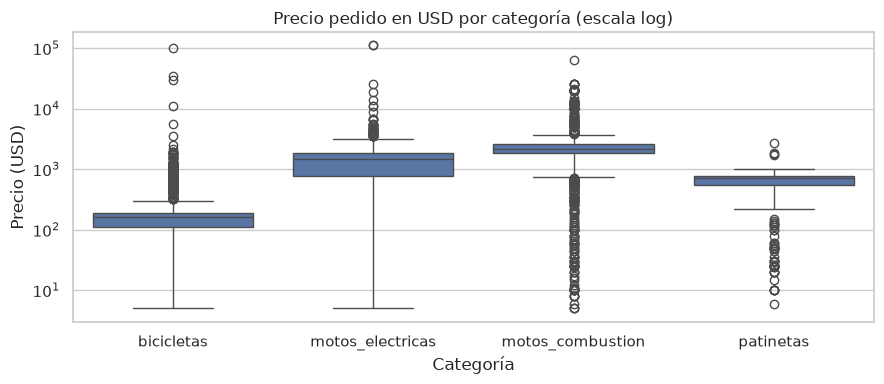

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=usd, x='categoria', y='precio', ax=ax)
ax.set_yscale('log')
ax.set_title('Precio pedido en USD por categoría (escala log)')
ax.set_xlabel('Categoría')
ax.set_ylabel('Precio (USD)')
plt.tight_layout()
plt.show()

## 6. Exportar el dataset limpio

Guardamos en UTF-8 con BOM para que Excel abra bien los acentos. Este es
el archivo que consume el notebook de EDA.

In [9]:
salida = DATA_PROCESSED / 'anuncios_limpios.csv'
limpio.to_csv(salida, index=False, encoding='utf-8-sig')
print('Guardado en:', salida)
print('Filas finales:', len(limpio))

Guardado en: /home/bri/proyectos/proyecto-mercado-vehiculos/data/processed/anuncios_limpios.csv
Filas finales: 9841


## 7. Checklist de limpieza

- [ ] Se documentó cuántos registros se descartaron y por qué.
- [ ] Se revisó una muestra manual de títulos para validar `marca` y `condicion`.
- [ ] Se decidió qué hacer con CUP (separar o convertir con tasa documentada).
- [ ] Los outliers se justificaron, no se borraron a ciegas.
- [ ] El dataset final conserva `fecha_captura`.
